# MOPITT MOP03JM — download only the greater-domain box

MOP03JM = MOPITT CO gridded **monthly** means, joint Near + Thermal IR retrieval (V010, LARC ASDC),
1°×1° global grid, ~144 MB per global file.

Instead of downloading global files, each month is subset **server-side** with NASA's cloud OPeNDAP:
only the grid cells inside the greater-domain box are transferred (all 86 variables, ~22 MB per month).

- **Bounding box** (lon_min, lat_min, lon_max, lat_max): `-173.215130, 4.498592, -48.619584, 72.872428`
  (same as `Scripts/greater-domain/crop_airs_greater_domain.ipynb`, grid-cell centres inside the box → 69 lat × 124 lon)
- **Output:** `Data/MOPITT-cropped-greater-domain/<YYYYMM>.nc` (e.g. `200301.nc`), dims `(lat, lon, ...)`

Steps: 1) download Jan 2003 and inspect it → 2) download every month Jan 2003 – Dec 2023.

In [1]:
# ── Config ────────────────────────────────────────────────────────────────────
import os
import time
import xml.etree.ElementTree as ET
import earthaccess
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Paths are relative to this notebook (Scripts/mopitt/)
PROJECT_DIR  = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
CROP_OUT_DIR = os.path.join(PROJECT_DIR, "Data", "MOPITT-cropped-greater-domain")
assert os.path.isdir(os.path.join(PROJECT_DIR, "Data")), f"Data folder not found  (cwd = {os.getcwd()})"
os.makedirs(CROP_OUT_DIR, exist_ok=True)

SHORT_NAME = "MOP03JM"
GRID_GROUP = "/HDFEOS/GRIDS/MOP03/Data_Fields"       # where the gridded variables live

# Greater North American domain (same as AIRS/CrIS): lon_min, lat_min, lon_max, lat_max
LON_MIN_C, LAT_MIN_C, LON_MAX_C, LAT_MAX_C = -173.215130, 4.498592, -48.619584, 72.872428

print(f"Output: {CROP_OUT_DIR}")

Output: d:\AIRS\harmonic-analysis\Data\MOPITT-cropped-greater-domain


In [2]:
# Uses ~/.netrc or EARTHDATA_USERNAME/EARTHDATA_PASSWORD if present, otherwise prompts
auth = earthaccess.login()
session = earthaccess.get_requests_https_session()     # authenticated session for OPeNDAP

In [3]:
# ── OPeNDAP helpers ───────────────────────────────────────────────────────────
def opendap_url(granule):
    """Cloud OPeNDAP URL of a granule (from its metadata)."""
    for u in granule["umm"].get("RelatedUrls", []):
        if u.get("Subtype") == "OPENDAP DATA":
            return u["URL"]
    raise ValueError("No OPeNDAP URL for " + granule["umm"]["GranuleUR"])


def granule_ym(granule):
    """(year, month) of a monthly granule."""
    t = granule["umm"]["TemporalExtent"]["RangeDateTime"]["BeginningDateTime"]
    return int(t[:4]), int(t[5:7])


def box_indices(url):
    """Index ranges (inclusive) of the grid-cell centres inside the box."""
    r = session.get(url + ".dap.nc4",
                    params={"dap4.ce": f"{GRID_GROUP}/Longitude;{GRID_GROUP}/Latitude"}, timeout=120)
    r.raise_for_status()
    with xr.open_dataset(r.content, group=GRID_GROUP) as c:
        lon, lat = c["Longitude"].values, c["Latitude"].values
    ix = np.where((lon >= LON_MIN_C) & (lon <= LON_MAX_C))[0]
    iy = np.where((lat >= LAT_MIN_C) & (lat <= LAT_MAX_C))[0]
    return (int(ix[0]), int(ix[-1])), (int(iy[0]), int(iy[-1]))


def build_ce(url, ix, iy):
    """DAP4 constraint: every variable in the grid group, XDim/YDim sliced to the box."""
    r = session.get(url + ".dmr.xml", timeout=120)
    r.raise_for_status()
    root = ET.fromstring(r.content)
    ns = {"d": root.tag.split("}")[0][1:]}
    grid = next(g for g in root.iter() if g.get("name") == GRID_GROUP.split("/")[-1])
    parts = []
    for v in grid:
        dims = [d.get("name").split("/")[-1] for d in v.findall("d:Dim", ns)]
        if v.tag.split("}")[1] in ("Group", "Attribute", "Dimension") or not dims:
            continue
        sl = "".join(f"[{ix[0]}:{ix[1]}]" if d == "XDim" else
                     f"[{iy[0]}:{iy[1]}]" if d == "YDim" else "[]" for d in dims)
        parts.append(f"{GRID_GROUP}/{v.get('name')}{sl}")
    return ";".join(parts)


def download_box(granule, out_path, ix, iy, retries=3):
    """Download the box subset of one granule and save it as a flat (lat, lon, ...) netCDF."""
    url = opendap_url(granule)
    for attempt in range(1, retries + 1):
        try:
            ce = build_ce(url, ix, iy)
            # POST: the constraint is too long for a URL (HTTP 414 with GET)
            r = session.post(url + ".dap.nc4", data={"dap4.ce": ce}, timeout=900)
            r.raise_for_status()
            break
        except Exception as e:
            print(f"    attempt {attempt} failed: {e}")
            if attempt == retries:
                raise
            time.sleep(10 * attempt)

    with xr.open_dataset(r.content, group=GRID_GROUP) as raw:
        ds = (raw.rename_dims({"XDim": "lon", "YDim": "lat"})
                 .assign_coords(lon=("lon", raw["Longitude"].values.astype("float64")),
                                lat=("lat", raw["Latitude"].values.astype("float64")))
                 .drop_vars(["Longitude", "Latitude"])
                 .transpose("lat", "lon", ...)
                 .load())

    for v in ds.variables.values():
        v.attrs.pop("fullnamepath", None)
    ds.attrs["crop_lon_min"] = LON_MIN_C
    ds.attrs["crop_lon_max"] = LON_MAX_C
    ds.attrs["crop_lat_min"] = LAT_MIN_C
    ds.attrs["crop_lat_max"] = LAT_MAX_C
    ds.attrs["source_file"]  = granule["umm"]["GranuleUR"]

    ds.to_netcdf(out_path, encoding={v: {"zlib": True, "complevel": 4} for v in ds.data_vars})
    return ds

## 1. One file: January 2003

In [4]:
# Confirm the collection version and find the Jan 2003 granule
for c in earthaccess.search_datasets(short_name=SHORT_NAME):
    print(c["umm"]["Version"], c["meta"]["provider-id"], c["umm"]["EntryTitle"])

results = earthaccess.search_data(short_name=SHORT_NAME, temporal=("2003-01-01", "2003-01-31"))
print(f"{len(results)} granule(s) found")
test_granule = results[0]
print("OPeNDAP:", opendap_url(test_granule))
test_granule

10 LARC_CLOUD MOPITT CO gridded monthly means (Near and Thermal Infrared Radiances) V010
1 granule(s) found
OPeNDAP: https://opendap.earthdata.nasa.gov/collections/C4191539031-LARC_CLOUD/granules/MOP03JM-200301-L3V98.0.3.he5


Collection: {'ShortName': 'MOP03JM', 'Version': '10'}
Spatial coverage: {'HorizontalSpatialDomain': {'Geometry': {'BoundingRectangles': [{'WestBoundingCoordinate': -180, 'EastBoundingCoordinate': 180, 'NorthBoundingCoordinate': 90, 'SouthBoundingCoordinate': -90}]}}}
Temporal coverage: {'RangeDateTime': {'BeginningDateTime': '2003-01-01T00:00:00.813000+00:00', 'EndingDateTime': '2003-01-01T23:59:59.999000+00:00'}}
Size(MB): 143.1448631286621
Data: ['https://data.asdc.earthdata.nasa.gov/asdc-prod-protected/MOPITT/MOP03JM.10/2003.01/MOP03JM-200301-L3V98.0.3.he5']

In [5]:
# Box indices on the MOPITT grid (same 1° grid for every month, so computed once)
IX, IY = box_indices(opendap_url(test_granule))
print(f"XDim (lon) indices {IX[0]}..{IX[1]}  ->  {IX[1] - IX[0] + 1} columns")
print(f"YDim (lat) indices {IY[0]}..{IY[1]}  ->  {IY[1] - IY[0] + 1} rows")

# Download the box subset of Jan 2003
y, m = granule_ym(test_granule)
test_out = os.path.join(CROP_OUT_DIR, f"{y}{m:02d}.nc")
t0 = time.time()
download_box(test_granule, test_out, IX, IY)
print(f"Saved -> {test_out}  ({os.path.getsize(test_out) / 1024**2:.1f} MB, {time.time() - t0:.0f} s)")

XDim (lon) indices 7..130  ->  124 columns
YDim (lat) indices 94..162  ->  69 rows
Saved -> d:\AIRS\harmonic-analysis\Data\MOPITT-cropped-greater-domain\200301.nc  (21.9 MB, 106 s)


## Inspect the downloaded file

In [7]:
ds_chk = xr.open_dataset(test_out)
print(dict(ds_chk.sizes))
print(f"lat {ds_chk.lat.values[0]} -> {ds_chk.lat.values[-1]},  lon {ds_chk.lon.values[0]} -> {ds_chk.lon.values[-1]}")
print({k: v for k, v in ds_chk.attrs.items()})
print()
for name, da in ds_chk.data_vars.items():
    print(f"{name:52s} {str(da.dims):32s} {da.attrs.get('units', '')}")

{'lat': 69, 'lon': 124, 'Prs1': 10, 'Prs2': 10, 'Prs': 9, 'NTWO': 2}
lat 4.5 -> 72.5,  lon -172.5 -> -49.5
{'crop_lon_min': np.float64(-173.21513), 'crop_lon_max': np.float64(-48.619584), 'crop_lat_min': np.float64(4.498592), 'crop_lat_max': np.float64(72.872428), 'source_file': 'MOP03JM-200301-L3V98.0.3.he5'}

RetrievalAveragingKernelMatrixDay                    ('lat', 'lon', 'Prs1', 'Prs2')   NA
MeasurementErrorCovarianceMatrixNight                ('lat', 'lon', 'Prs1', 'Prs2')   NA
APrioriSurfaceEmissivityNight                        ('lat', 'lon')                   NA
RetrievalAveragingKernelMatrixNight                  ('lat', 'lon', 'Prs1', 'Prs2')   NA
DegreesofFreedomforSignalDay                         ('lat', 'lon')                   NA
RetrievedCOSurfaceMixingRatioDay                     ('lat', 'lon')                   ppbv
SatelliteZenithAngleNight                            ('lat', 'lon')                   deg
DryAirColumnNight                                    ('lat', 

RetrievedCOTotalColumnDay: valid 79.0%, min 1.293e+18, mean 2.023e+18, max 4.437e+18 molecules/cm^2
RetrievedCOTotalColumnNight: valid 96.2%, min 1.293e+18, mean 2.074e+18, max 3.087e+18 molecules/cm^2


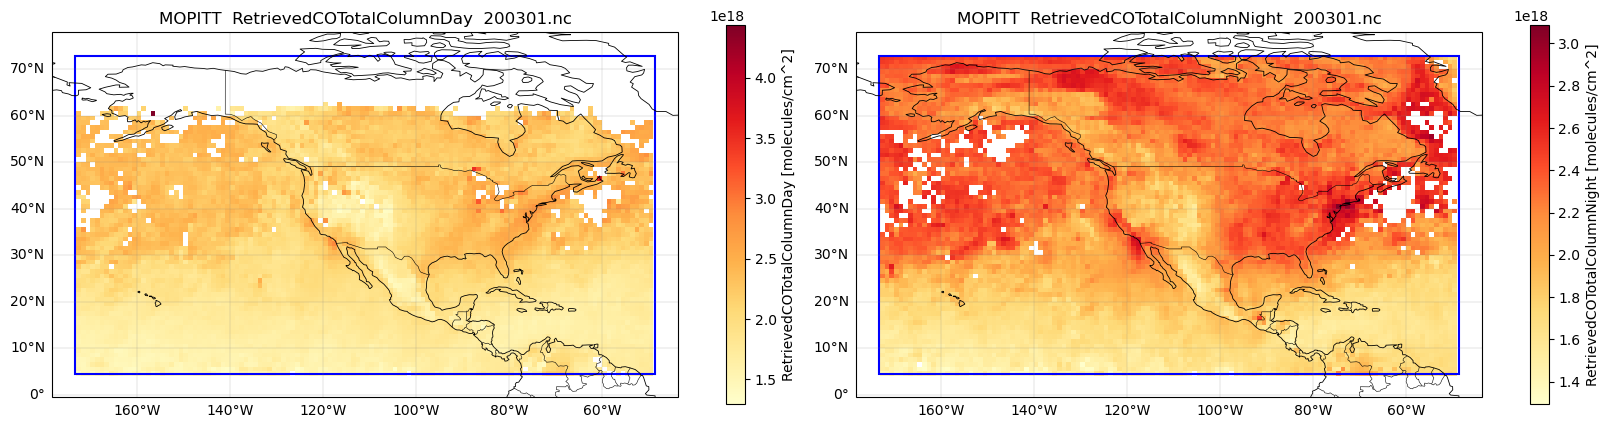

In [8]:
# Quick look: day & night CO total column with the crop box
pad = 5
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), subplot_kw={"projection": ccrs.PlateCarree()},
                         constrained_layout=True)
for ax, var in zip(axes, ["RetrievedCOTotalColumnDay", "RetrievedCOTotalColumnNight"]):
    da = ds_chk[var]
    print(f"{var}: valid {float(da.notnull().mean()):.1%}, "
          f"min {float(da.min()):.3e}, mean {float(da.mean()):.3e}, max {float(da.max()):.3e} {da.attrs.get('units', '')}")
    mesh = ax.pcolormesh(ds_chk.lon, ds_chk.lat, da, transform=ccrs.PlateCarree(),
                         cmap="YlOrRd", shading="auto")
    ax.coastlines(linewidth=0.6)
    ax.add_feature(cfeature.BORDERS, linewidth=0.4)
    ax.add_patch(mpatches.Rectangle((LON_MIN_C, LAT_MIN_C), LON_MAX_C - LON_MIN_C, LAT_MAX_C - LAT_MIN_C,
                                    fill=False, edgecolor="blue", linewidth=1.5, transform=ccrs.PlateCarree()))
    ax.set_extent([LON_MIN_C - pad, LON_MAX_C + pad, LAT_MIN_C - pad, LAT_MAX_C + pad], crs=ccrs.PlateCarree())
    gl = ax.gridlines(draw_labels=True, linewidth=0.3, color="gray", alpha=0.5)
    gl.top_labels = gl.right_labels = False
    fig.colorbar(mesh, ax=ax, shrink=0.7, label=f"{var} [{da.attrs.get('units', '')}]")
    ax.set_title(f"MOPITT  {var}  {os.path.basename(test_out)}")
plt.show()
ds_chk.close()

## 2. All months: Jan 2003 – Dec 2023

Months already in the output folder are skipped, so this cell can be re-run to resume an interrupted download.

In [9]:
# Search every monthly granule in the window
all_results = earthaccess.search_data(short_name=SHORT_NAME, temporal=("2003-01-01", "2023-12-31"))

found = sorted(granule_ym(g) for g in all_results)
expected = [(y, m) for y in range(2003, 2024) for m in range(1, 13)]
missing = [f"{y}-{m:02d}" for (y, m) in expected if (y, m) not in found]

print(f"{len(all_results)} granules found  ({found[0][0]}-{found[0][1]:02d} - {found[-1][0]}-{found[-1][1]:02d})")
print(f"Expected months : {len(expected)}")
print(f"Missing months  : {len(missing)}  {missing}")

250 granules found  (2003-01 - 2023-12)
Expected months : 252
Missing months  : 2  ['2009-08', '2009-09']


In [10]:
# ── Download the box subset of ALL months ────────────────────────────────────
# Output: Data/MOPITT-cropped-greater-domain/<YYYYMM>.nc  (e.g. 200301.nc, 200302.nc …)
OVERWRITE = False   # True → re-download files that already exist

saved, skipped, failed = [], [], []
t_start = time.time()

for g in sorted(all_results, key=granule_ym):
    year, month = granule_ym(g)
    out_name = f"{year}{month:02d}.nc"
    out_path = os.path.join(CROP_OUT_DIR, out_name)

    if os.path.exists(out_path) and not OVERWRITE:
        print(f"  [exists] {out_name} – skipping")
        skipped.append(out_name)
        continue

    t0 = time.time()
    try:
        download_box(g, out_path, IX, IY)
    except Exception as e:
        print(f"  [FAILED] {out_name}: {e}")
        if os.path.exists(out_path):
            os.remove(out_path)          # never leave a partial file behind
        failed.append(out_name)
        continue

    print(f"  [saved] {out_name}  ({os.path.getsize(out_path) / 1024**2:.1f} MB, {time.time() - t0:.0f} s)")
    saved.append(out_name)

print(f"\nDone in {(time.time() - t_start) / 60:.1f} min.  Saved {len(saved)}  |  Skipped {len(skipped)}  |  Failed {len(failed)} {failed}")
print(f"Output folder: {CROP_OUT_DIR}")

  [exists] 200301.nc – skipping
  [saved] 200302.nc  (23.2 MB, 18 s)
  [saved] 200303.nc  (24.2 MB, 19 s)
  [saved] 200304.nc  (24.4 MB, 27 s)
  [saved] 200305.nc  (24.5 MB, 36 s)
  [saved] 200306.nc  (24.2 MB, 19 s)
  [saved] 200307.nc  (24.8 MB, 32 s)
  [saved] 200308.nc  (24.7 MB, 42 s)
  [saved] 200309.nc  (24.5 MB, 22 s)
  [saved] 200310.nc  (24.1 MB, 26 s)
  [saved] 200311.nc  (22.4 MB, 14 s)
  [saved] 200312.nc  (18.5 MB, 15 s)
  [saved] 200401.nc  (17.3 MB, 22 s)
  [saved] 200402.nc  (23.3 MB, 18 s)
  [saved] 200403.nc  (24.1 MB, 15 s)
  [saved] 200404.nc  (24.6 MB, 16 s)
  [saved] 200405.nc  (24.5 MB, 19 s)
  [saved] 200406.nc  (24.1 MB, 15 s)
  [saved] 200407.nc  (24.6 MB, 24 s)
  [saved] 200408.nc  (24.7 MB, 18 s)
  [saved] 200409.nc  (24.4 MB, 26 s)
  [saved] 200410.nc  (23.8 MB, 19 s)
  [saved] 200411.nc  (22.6 MB, 14 s)
  [saved] 200412.nc  (21.5 MB, 16 s)
  [saved] 200501.nc  (22.1 MB, 47 s)
  [saved] 200502.nc  (23.5 MB, 74 s)
  [saved] 200503.nc  (24.5 MB, 19 s)
  [sav

In [11]:
# Verify: every month opens, has the box grid, and has data
problems = []
for g in sorted(all_results, key=granule_ym):
    year, month = granule_ym(g)
    fp = os.path.join(CROP_OUT_DIR, f"{year}{month:02d}.nc")
    if not os.path.exists(fp):
        problems.append((os.path.basename(fp), "missing"))
        continue
    try:
        with xr.open_dataset(fp) as d:
            if (d.sizes["lat"], d.sizes["lon"]) != (IY[1] - IY[0] + 1, IX[1] - IX[0] + 1):
                problems.append((os.path.basename(fp), f"grid {dict(d.sizes)}"))
            elif int(d["RetrievedCOTotalColumnDay"].notnull().sum()) == 0:
                problems.append((os.path.basename(fp), "no valid RetrievedCOTotalColumnDay"))
    except Exception as e:
        problems.append((os.path.basename(fp), f"unreadable: {e}"))

on_disk = sorted(f for f in os.listdir(CROP_OUT_DIR) if f.endswith(".nc"))
print(f"Files on disk : {len(on_disk)}  ({on_disk[0]} ... {on_disk[-1]})")
print(f"Total on disk : {sum(os.path.getsize(os.path.join(CROP_OUT_DIR, f)) for f in on_disk) / 1024**3:.2f} GB")
print("Problems      :", problems if problems else "none")
# To fix a problem file: delete it and re-run the download cell above.

Files on disk : 250  (200301.nc ... 202312.nc)
Total on disk : 5.74 GB
Problems      : none
